# Tech Challenge - Fase 02
## Case Wine Quality

## Contexto

A indústria vitivinícola possui grande relevância econômica e cultural em diversos países. Tradicionalmente, a avaliação da qualidade de um vinho é realizada por especialistas, por meio de análises sensoriais, que consideram aspectos como aroma, sabor, acidez e equilíbrio. No entanto, esse processo pode ser subjetivo e demandar tempo, além de depender da experiência dos avaliadores.

Com o avanço das técnicas de ciência de dados e aprendizado de máquina, tornou-se possível utilizar dados físico-químicos obtidos durante a produção do vinho para auxiliar na previsão da qualidade final do produto. Dessa forma, modelos preditivos podem apoiar enólogos e produtores na tomada de decisão, permitindo ajustes no processo produtivo e contribuindo para a padronização da qualidade.

## Proposta

O objetivo é desenvolver e treinar um modelo de classificação capaz de prever a qualidade do vinho com base nas características físico-químicas. A variável quality será transformada em uma classificação binária:

- **Vinho de Alta Qualidade (1)**: nota ≥ 7
- **Vinho de Qualidade Comum (0)**: nota < 7

Vale ressaltar que a base contém somente vinhos tintos da variedade portuguesa Vinho Verde. Portanto, as conclusões valem para este recorte.

Fonte: https://www.kaggle.com/datasets/yasserh/wine-quality-dataset

# Setup

In [35]:
RANDOM_STATE = 42

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             precision_score, recall_score, f1_score, accuracy_score,
                             RocCurveDisplay)

sns.set_theme(style="whitegrid")

In [37]:
# Inclusões para aproveitar os modelos e avaliações do notebook 2.
# As importações e os textos originais foram preservados.

from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

In [38]:
URL = "https://raw.githubusercontent.com/rons-12/fiap-tech-challenge-fase-2-wine-quality/main/data/WineQT.csv"
df = pd.read_csv(URL)

# Etapa 1: Compreensão do Problema e preparação da base

In [39]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [40]:
df.shape

(1143, 13)

In [41]:
# Remoção da coluna "Id" (é apenas um índice, sem caracteristicas do vinho),
# e remoção das linhas duplicadas.

df = df.drop(columns="Id")
n_antes = len(df)
df = df.drop_duplicates()
df = df.reset_index(drop=True)

In [42]:
print(f"Duplicatas removidas:{n_antes - len(df)} | Linhas finais: {len(df)}")

Duplicatas removidas:125 | Linhas finais: 1018


In [43]:
# Criação de classificação binária.
# 1 = Alta Qualidade (nota >=7),
# 0 = Qualidade Comum (nota <7)
df["alta_qualidade"] = (df["quality"] >= 7).astype(int)

# Remoção das colunas "quality" e "alta_qualidade", pois elas são o resultado.
# Mante-las na variável X faria termos vazamento de dados.
x = df.drop(columns=["quality", "alta_qualidade"])
y = df["alta_qualidade"]
y.value_counts(normalize=True)

,proportion
alta_qualidade,
0,0.865422
1,0.134578


In [44]:
# Divisão treino/teste: 70/30. Mantemos assim aproximadametne
# 13,5% de vinhos bons em ambos os conjutos.
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)

print(f"Treino: {x_train.shape[0]} vinhos ({y_train.mean():.1%} alta qualidade)")
print(f"Teste:  {x_test.shape[0]} vinhos ({y_test.mean():.1%} alta qualidade)")

Treino: 712 vinhos (13.5% alta qualidade)
Teste:  306 vinhos (13.4% alta qualidade)


In [45]:
x

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8
4,7.4,0.660,0.00,1.8,0.075,13.0,40.0,0.99780,3.51,0.56,9.4
...,...,...,...,...,...,...,...,...,...,...,...
1013,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0
1014,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5
1015,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5
1016,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2


# Etapa 2: Análise Exploratória - EDA
Como primeiro passo, vamos entender o comportamento estatístico dos dados físico-químicos (como acidez, pH, teor alcoólico).

## 2.1 - Investigando a distribuição das variáveis e detectando outliers

In [46]:
## Visão geral do Dataframe após as transformações anteriores.
## A fim de validar se não ficou nada fora do lugar

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1018 entries, 0 to 1017
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1018 non-null   float64
 1   volatile acidity      1018 non-null   float64
 2   citric acid           1018 non-null   float64
 3   residual sugar        1018 non-null   float64
 4   chlorides             1018 non-null   float64
 5   free sulfur dioxide   1018 non-null   float64
 6   total sulfur dioxide  1018 non-null   float64
 7   density               1018 non-null   float64
 8   pH                    1018 non-null   float64
 9   sulphates             1018 non-null   float64
 10  alcohol               1018 non-null   float64
 11  quality               1018 non-null   int64  
 12  alta_qualidade        1018 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 103.5 KB


In [47]:
## Detectando a presença de valores nulos ou negativos/impossíveis

print("Valores nulos por colunas:", int(df.isnull().sum().sum()))
df.describe().T.round(3)

Valores nulos por colunas: 0


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1018.0,8.289,1.741,4.600,7.100,7.900,9.100,15.900
volatile acidity,1018.0,0.534,0.183,0.120,0.390,0.520,0.645,1.580
citric acid,1018.0,0.269,0.196,0.000,0.090,0.250,0.420,1.000
residual sugar,1018.0,2.524,1.315,0.900,1.900,2.200,2.600,15.500
chlorides,1018.0,0.087,0.049,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1018.0,15.649,10.177,1.000,7.000,13.000,21.000,68.000
total sulfur dioxide,1018.0,46.326,33.124,6.000,21.000,38.000,62.000,289.000
density,1018.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1018.0,3.312,0.158,2.740,3.210,3.310,3.400,4.010
sulphates,1018.0,0.657,0.168,0.330,0.550,0.620,0.720,2.000


Não há valores nulos nem valores impossíveis.

## 2.2 - Distribuição das variáveis

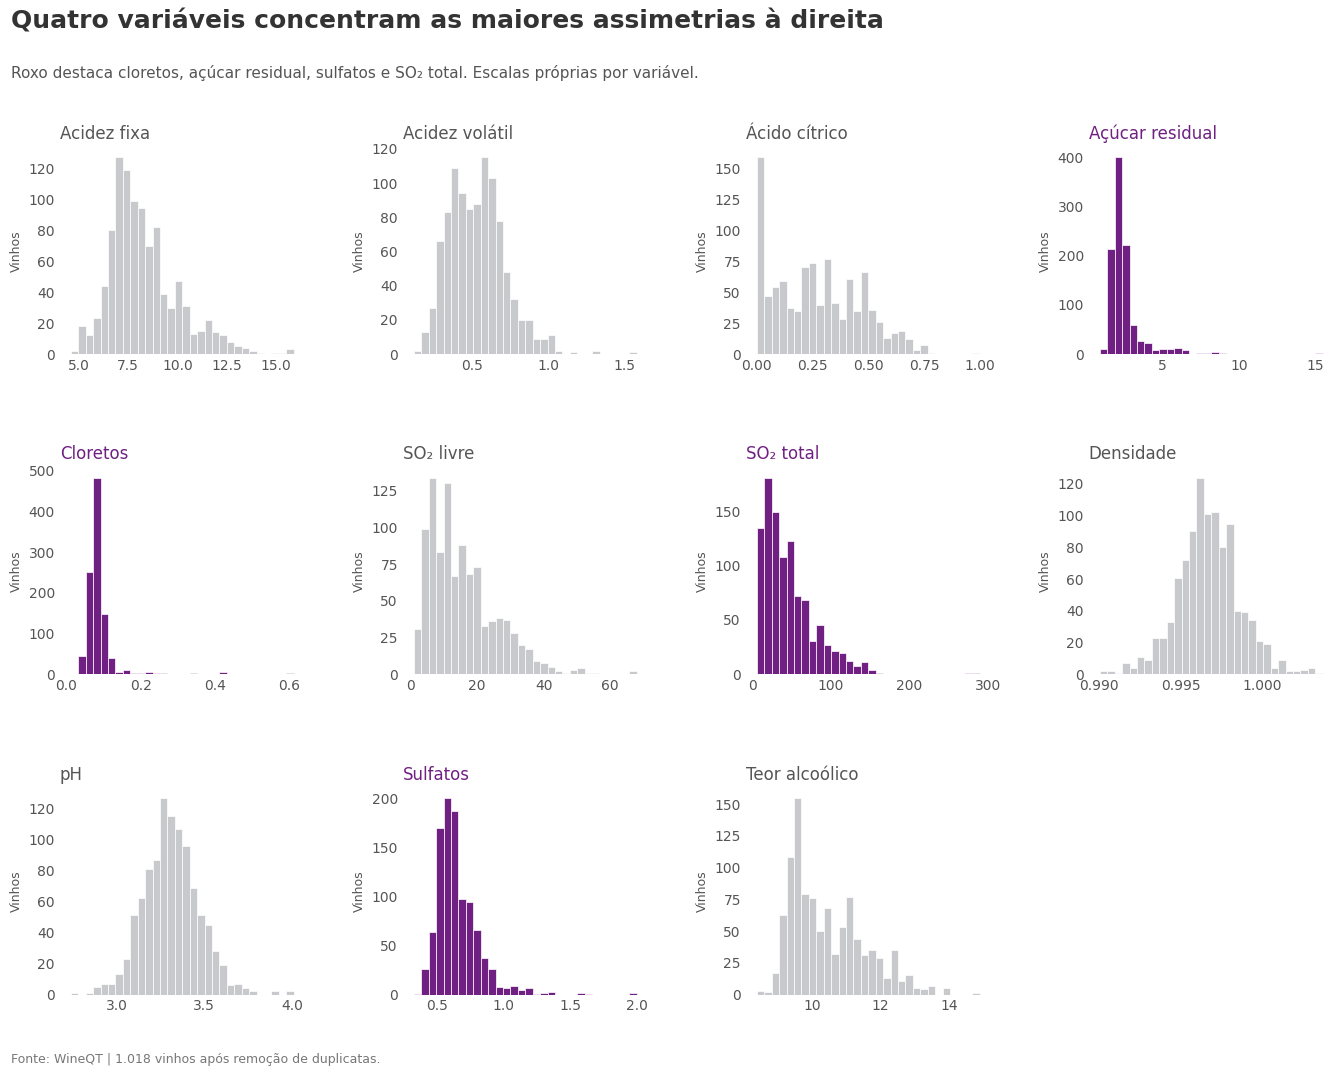

In [48]:
# Ajuste apenas visual inspirado em Storytelling with Data:
# fundo limpo, títulos informativos, rótulos em português e destaque seletivo.
# As funções abaixo formatam somente as figuras; não alteram os dados.
SWD_ROXO = "#702082"
SWD_CINZA = "#C7C9CD"
SWD_ESCURO = "#555555"
SWD_NOMES = {
    "fixed acidity": "Acidez fixa", "volatile acidity": "Acidez volátil",
    "citric acid": "Ácido cítrico", "residual sugar": "Açúcar residual",
    "chlorides": "Cloretos", "free sulfur dioxide": "SO₂ livre",
    "total sulfur dioxide": "SO₂ total", "density": "Densidade",
    "pH": "pH", "sulphates": "Sulfatos", "alcohol": "Teor alcoólico"
}
def swd_limpar(ax):
    ax.set_facecolor("white")
    ax.grid(False)
    for borda in ax.spines.values():
        borda.set_visible(False)
    ax.tick_params(axis="both", length=0, labelcolor=SWD_ESCURO, labelsize=10)

def swd_titulo(fig, titulo, subtitulo, rodape):
    fig.set_facecolor("white")
    fig.text(0.035, 0.975, titulo, ha="left", va="top", fontsize=18,
             fontweight="bold", color="#333333")
    fig.text(0.035, 0.925, subtitulo, ha="left", va="top", fontsize=11, color=SWD_ESCURO)
    fig.text(0.035, 0.015, rodape, ha="left", va="bottom", fontsize=9, color="#777777")

def swd_salvar(fig, nome):
    fig.savefig(nome, dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

swd_assimetricas = set(x.skew().nlargest(4).index)
fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for ax, col in zip(axes.flat, x.columns):
    destaque = col in swd_assimetricas
    ax.hist(x[col], bins=30, color=SWD_ROXO if destaque else SWD_CINZA,
             edgecolor="white", linewidth=0.5)
    swd_limpar(ax)
    ax.set_title(SWD_NOMES.get(col, col), loc="left", fontsize=12,
                 color=SWD_ROXO if destaque else SWD_ESCURO)
    ax.set_ylabel("Vinhos", fontsize=9, color=SWD_ESCURO)
fig.delaxes(axes.flat[-1])
swd_titulo(fig, "Quatro variáveis concentram as maiores assimetrias à direita",
           "Roxo destaca cloretos, açúcar residual, sulfatos e SO₂ total. Escalas próprias por variável.",
           f"Fonte: WineQT | {len(df):,} vinhos após remoção de duplicatas.".replace(",", "."))
fig.subplots_adjust(top=0.85, bottom=0.08, left=0.07, right=0.98, hspace=0.55, wspace=0.40)
swd_salvar(fig, "hist_variaveis.png")

In [49]:
# Quanto maior a assimetria, mais longa a cauda à direita
x.skew().sort_values(ascending=False).round(2).to_frame("assimetria")

,assimetria
chlorides,5.93
residual sugar,4.35
sulphates,2.42
total sulfur dioxide,1.68
free sulfur dioxide,1.17
fixed acidity,1.04
alcohol,0.85
volatile acidity,0.72
citric acid,0.37
pH,0.26


Podemos notar que as variáveis cloretos *(chlorides)*, açucar residual *(residual sugar)*, sulfatos *(sulphates)* e dióxido de enxofre total *(total sulfur dioxide)* apresentam uma forte assimetria à direita, sendo que a maioria dos vinhos concentram valores baixos, com poucos casos extremos, isso pode indicar possíveis outiliers. Para essas variáveis a mediana é mais indicada por descrever melhor o vinho, do que a média.

Outro ponto, é outras variáveis como densidade *(density)*, pH e ácido cítrico *(citric acid)* tem uma distribuição mais próxima da simétrica.

## 2.3 - Balanceamento das Classes

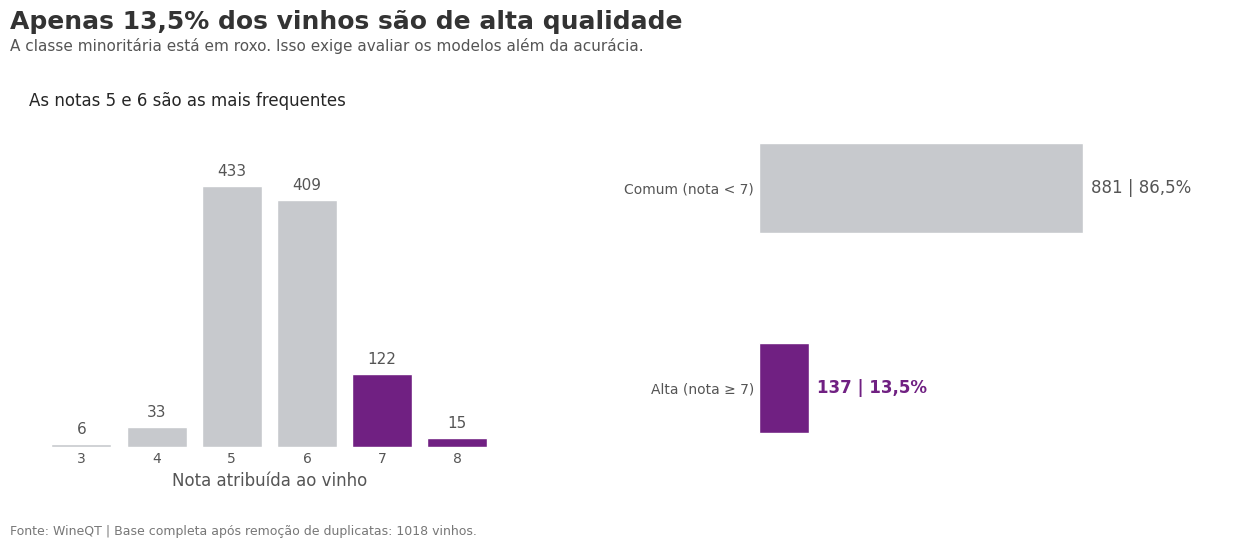

In [50]:
# Ajuste visual: a classe minoritária recebe destaque; valores junto às barras.
# Preservadas as duas informações originais: notas e classificação binária.
notas = df["quality"].value_counts().sort_index()
classes = y.value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
barras = axes[0].bar(notas.index.astype(str), notas.values,
                    color=[SWD_ROXO if n >= 7 else SWD_CINZA for n in notas.index])
axes[0].bar_label(barras, padding=5, fontsize=11, color=SWD_ESCURO)
axes[0].set_ylim(0, notas.max()*1.22)
axes[0].set_yticks([])
axes[0].set_xlabel("Nota atribuída ao vinho", color=SWD_ESCURO)
axes[0].set_title("As notas 5 e 6 são as mais frequentes", loc="left", fontsize=12, pad=16)
axes[1].barh([0,1], classes.values, color=[SWD_CINZA, SWD_ROXO], height=0.45)
axes[1].set_yticks([0,1], ["Comum (nota < 7)", "Alta (nota ≥ 7)"])
axes[1].invert_yaxis()
axes[1].set_xlim(0, len(y)*1.28)
axes[1].set_xticks([])
for pos, (classe, v) in enumerate(classes.items()):
    rotulo=f"{v} | {v/len(y):.1%}".replace(".", ",")
    axes[1].text(v+len(y)*0.02, pos, rotulo, va="center", fontsize=12,
                 color=SWD_ROXO if classe==1 else SWD_ESCURO,
                 fontweight="bold" if classe==1 else "normal")
for ax in axes: swd_limpar(ax)
pct=f"{100*y.mean():.1f}".replace(".", ",")
swd_titulo(fig, f"Apenas {pct}% dos vinhos são de alta qualidade",
           "A classe minoritária está em roxo. Isso exige avaliar os modelos além da acurácia.",
           f"Fonte: WineQT | Base completa após remoção de duplicatas: {len(y)} vinhos.")
fig.subplots_adjust(left=0.05, right=0.98, top=0.76, bottom=0.18, wspace=0.52)
swd_salvar(fig, "balanceamento_classes.png")

**O que observamos aqui:** 881 vinhos receberam notas de 3 a 6 e são classificados como vinhos comuns (86,5%). A maior parte parte deles recebeu nota 5 ou 6 (842). Como sabemos, os especialistas dificilmente dão notas extremas, com isso temos 137 vinhos que receberam notas iguais ou superiores a 7, representando 13,5% de vinhos de Alta classe.

## 2.4 - Correlações
A matriz de correlação ajuda a entender quais características físico-químicas mais influenciam a nota do vinho (e a nossa variável target).

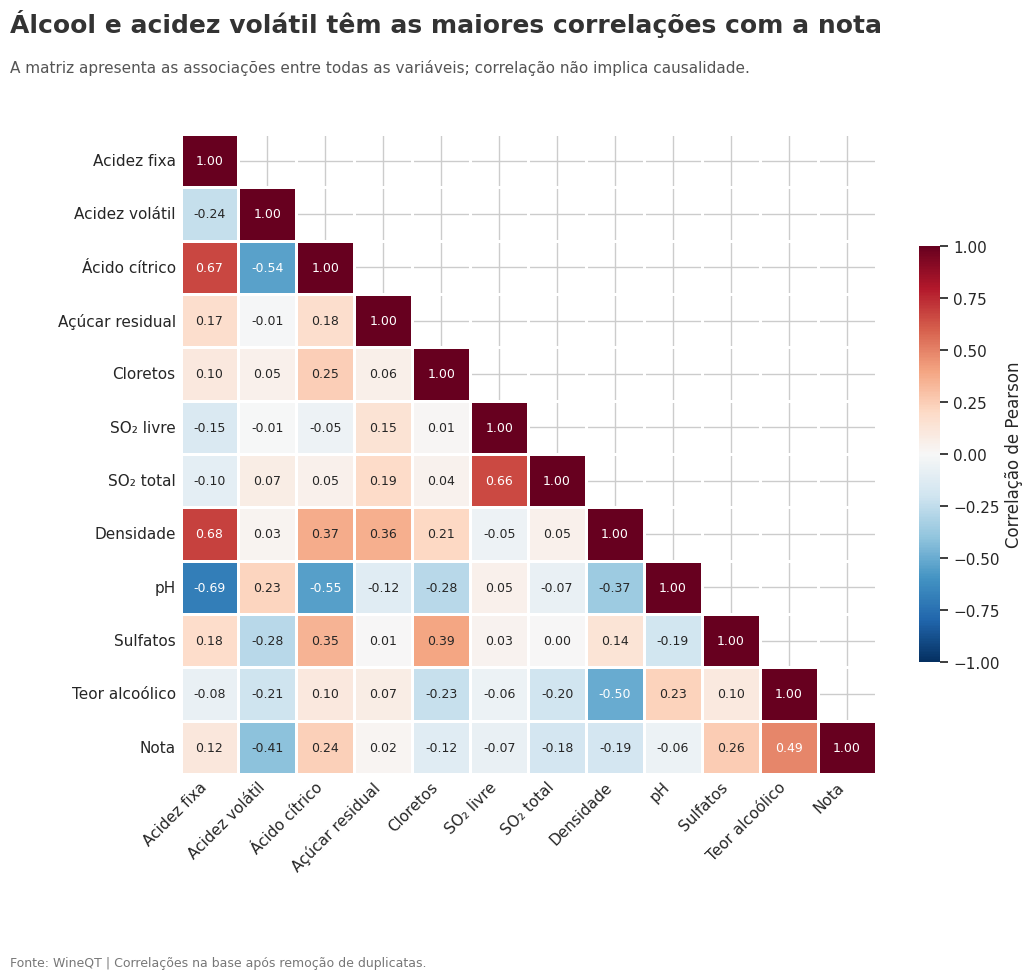

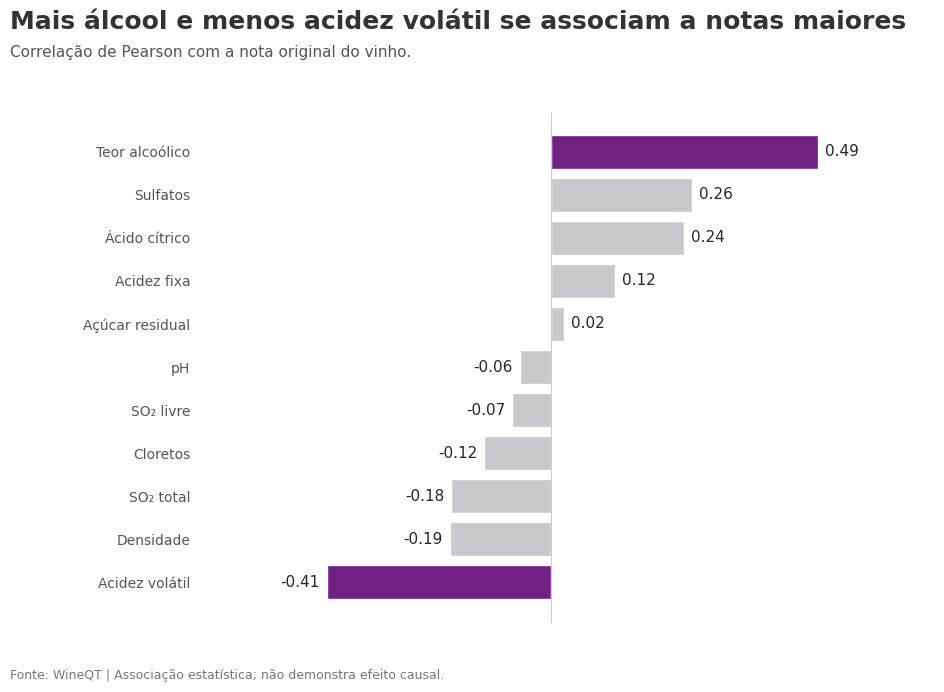

,correlação com quality
volatile acidity,-0.41
density,-0.19
total sulfur dioxide,-0.18
chlorides,-0.12
free sulfur dioxide,-0.07
pH,-0.06
residual sugar,0.02
fixed acidity,0.12
citric acid,0.24
sulphates,0.26


In [51]:
# Ajuste visual: mantida a matriz completa e adicionada leitura direta das
# correlações com a nota. A cor destaca as duas associações de maior magnitude.
corr = df.drop(columns="alta_qualidade").corr()
fig, ax = plt.subplots(figsize=(11, 10))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
swd_corr_rotulos = corr.rename(index=SWD_NOMES, columns=SWD_NOMES).rename(
    index={"quality":"Nota"}, columns={"quality":"Nota"})
sns.heatmap(swd_corr_rotulos, mask=mask, annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=1,
            linecolor="white", annot_kws={"size":9}, ax=ax,
            cbar_kws={"shrink":0.65, "label":"Correlação de Pearson"})
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.tick_params(length=0)
swd_titulo(fig, "Álcool e acidez volátil têm as maiores correlações com a nota",
           "A matriz apresenta as associações entre todas as variáveis; correlação não implica causalidade.",
           "Fonte: WineQT | Correlações na base após remoção de duplicatas.")
fig.subplots_adjust(top=0.85, bottom=0.21, left=0.19, right=0.98)
swd_salvar(fig, "matriz_correlacao.png")

swd_corr_nota = corr["quality"].drop("quality").sort_values()
fig, ax = plt.subplots(figsize=(10, 7))
cores = [SWD_ROXO if c in ["alcohol", "volatile acidity"] else SWD_CINZA for c in swd_corr_nota.index]
barras=ax.barh([SWD_NOMES.get(c,c) for c in swd_corr_nota.index], swd_corr_nota.values, color=cores)
ax.bar_label(barras, fmt="%.2f", padding=5, fontsize=11)
ax.axvline(0, color="#CCCCCC", linewidth=0.8)
ax.set_xlim(-0.65,0.7)
ax.set_xticks([])
swd_limpar(ax)
swd_titulo(fig, "Mais álcool e menos acidez volátil se associam a notas maiores",
           "Correlação de Pearson com a nota original do vinho.",
           "Fonte: WineQT | Associação estatística; não demonstra efeito causal.")
fig.subplots_adjust(top=0.83, bottom=0.10, left=0.22, right=0.96)
swd_salvar(fig, "correlacoes_com_nota.png")

corr["quality"].drop("quality").sort_values().round(2).to_frame("correlação com quality")

`(Texto base da Fernanda, com valores recalculados)`

**Correlações com a qualidade:**


1.   **Teor Alcoólico (alcohol, +0,49):** Vinhos de maior qualidade tendem a apresentar uma correlação positiva moderada/forte com o teor alcoólico;
2.   **Acidez Volátil (volatile acidity, -0,41):** Apresentou uma correlação negativa com a qualidade, pois níveis muito altos de acidez volátil dão um sabor desagradável (vinagre) ao vinho;
3.   **Sulfatos (sulphates, +0,26):** Níveis adequados de sulfatos funcionam como um indicador de estabilidade e bom armazenamento, protegendo o vinho contra oxidações que degradariam a nota;
4.   **Ácido cítrico (citric acid, +0,24):** contribui com frescor.

**Correlações entre as variáveis:** fixed acidity se relaciona com citric acid (+0,67), density (+0,68) e pH (−0,69), o que é esperado quimicamente (mais ácido → pH menor). free e total sulfur dioxide também andam juntos (+0,66). Nenhum par passa de 0,7, então não há redundância grave a ponto de exigir remover variáveis.

## 2.5 - A diferença entre um vinho bom de um comum

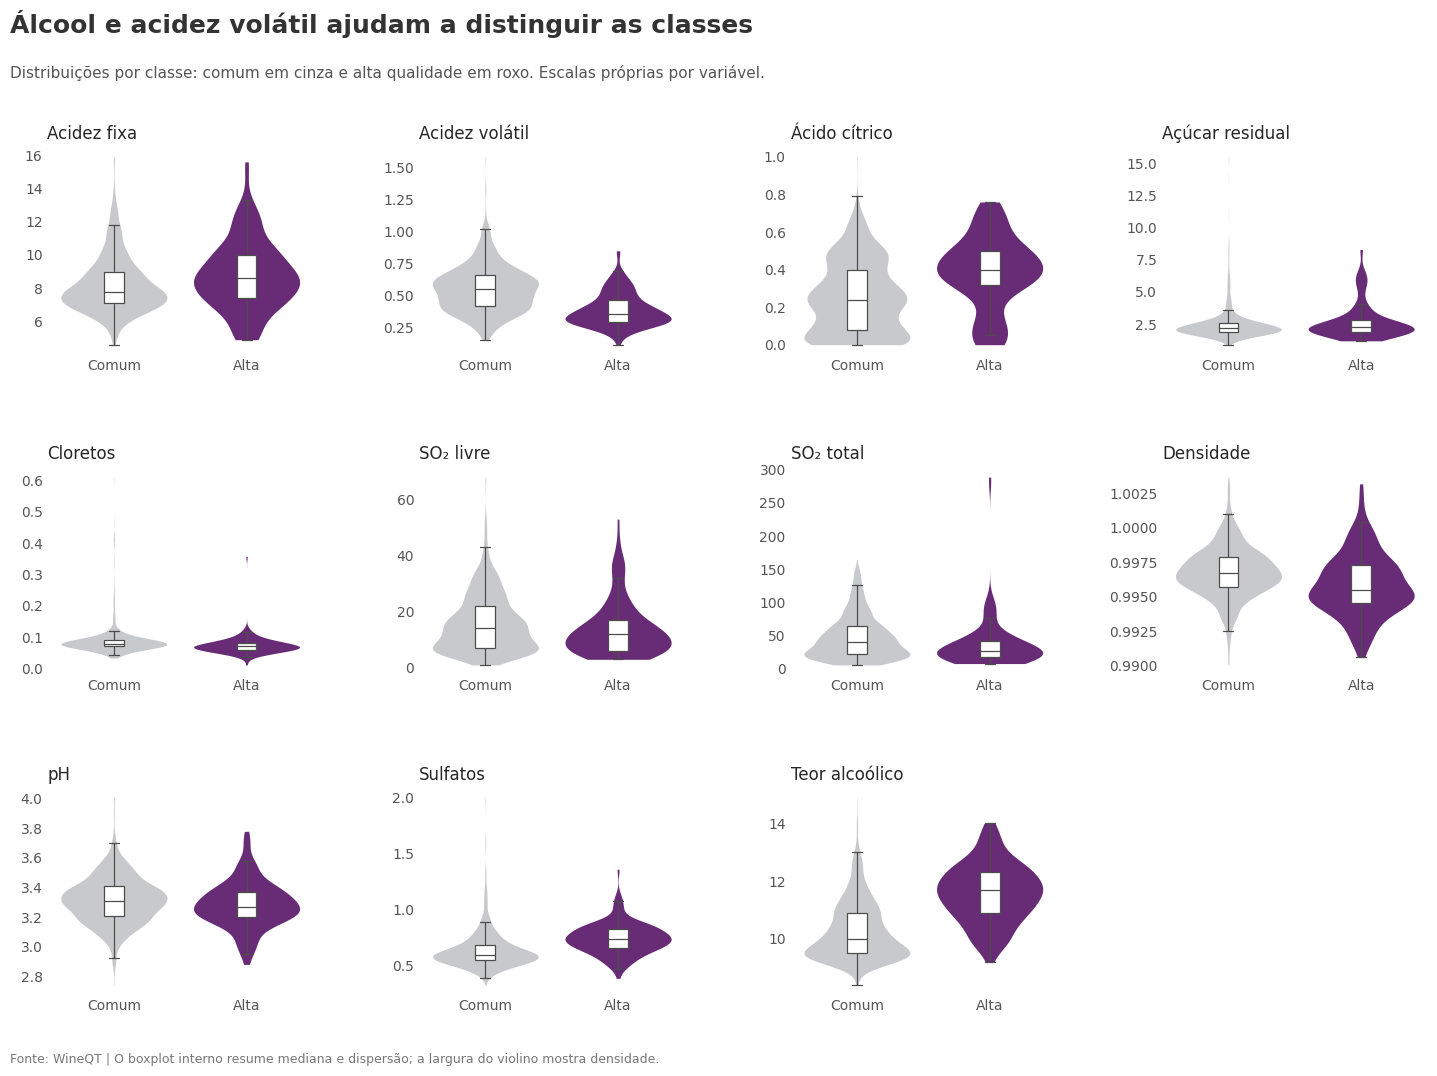

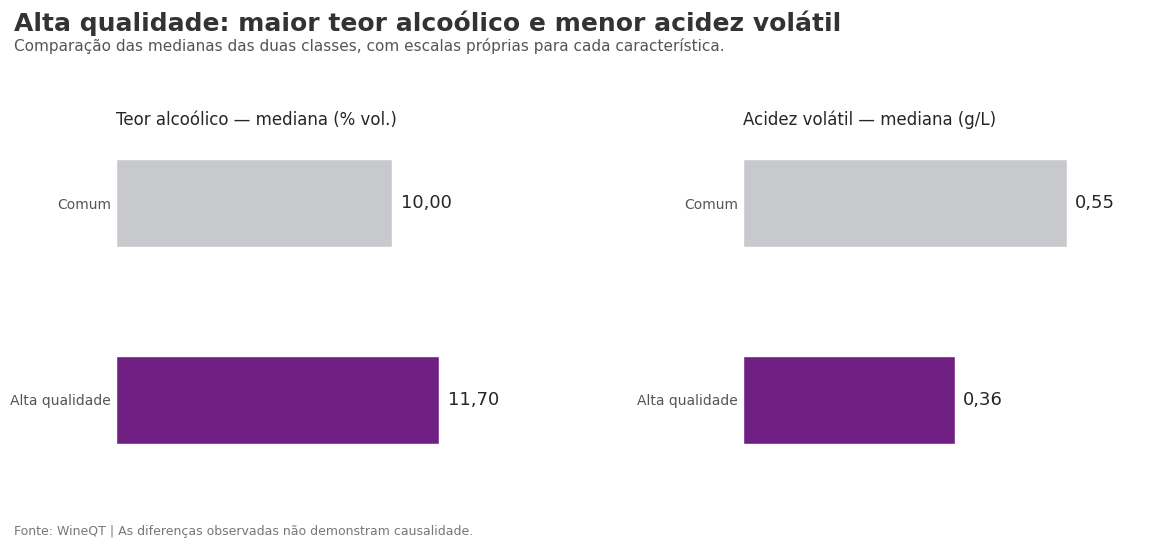

alta_qualidade,mediana comum,mediana alta
fixed acidity,7.800,8.600
volatile acidity,0.550,0.360
citric acid,0.240,0.400
residual sugar,2.200,2.300
chlorides,0.080,0.071
free sulfur dioxide,14.000,12.000
total sulfur dioxide,41.000,27.000
density,0.997,0.995
pH,3.310,3.270
sulphates,0.600,0.740


In [52]:
# Ajuste visual: cinza para a classe comum e roxo para alta qualidade.
# Distribuições completas mantidas; um resumo de medianas facilita a apresentação.
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(15, 11))
axes = axes.flatten()
paleta = {0: SWD_CINZA, 1: SWD_ROXO}
for i, col in enumerate(x.columns):
    sns.violinplot(data=df, x="alta_qualidade", y=col, hue="alta_qualidade",
                   palette=paleta, ax=axes[i], inner=None, legend=False,
                   linewidth=0, density_norm="width", cut=0)
    sns.boxplot(data=df, x="alta_qualidade", y=col, ax=axes[i], width=0.15,
                showfliers=False, boxprops={"facecolor":"white"}, linewidth=0.9)
    swd_limpar(axes[i])
    axes[i].set_title(SWD_NOMES.get(col,col), loc="left", fontsize=12)
    axes[i].set_xlabel(""); axes[i].set_ylabel("")
    axes[i].set_xticks([0,1], ["Comum", "Alta"])
fig.delaxes(axes[-1])
swd_titulo(fig, "Álcool e acidez volátil ajudam a distinguir as classes",
           "Distribuições por classe: comum em cinza e alta qualidade em roxo. Escalas próprias por variável.",
           "Fonte: WineQT | O boxplot interno resume mediana e dispersão; a largura do violino mostra densidade.")
fig.subplots_adjust(top=0.85, bottom=0.08, left=0.06, right=0.98, hspace=0.55, wspace=0.40)
swd_salvar(fig, "variaveis_por_classes.png")

fig, axes = plt.subplots(1,2, figsize=(12,5.5))
for ax, col, titulo in zip(axes, ["alcohol", "volatile acidity"],
                           ["Teor alcoólico — mediana (% vol.)", "Acidez volátil — mediana (g/L)"]):
    valores = df.groupby("alta_qualidade")[col].median().reindex([0,1])
    barras=ax.barh([0,1], valores.values, color=[SWD_CINZA,SWD_ROXO], height=0.45)
    ax.set_yticks([0,1],["Comum", "Alta qualidade"]); ax.invert_yaxis()
    ax.set_xlim(0,valores.max()*1.25); ax.set_xticks([])
    ax.bar_label(barras, labels=[f"{v:.2f}".replace(".",",") for v in valores], padding=6, fontsize=13)
    swd_limpar(ax); ax.set_title(titulo, loc="left", fontsize=12, pad=14)
swd_titulo(fig, "Alta qualidade: maior teor alcoólico e menor acidez volátil",
           "Comparação das medianas das duas classes, com escalas próprias para cada característica.",
           "Fonte: WineQT | As diferenças observadas não demonstram causalidade.")
fig.subplots_adjust(top=0.73,bottom=0.16,left=0.12,right=0.98,wspace=0.55)
swd_salvar(fig,"medianas_por_classe.png")

df.groupby("alta_qualidade")[list(x.columns)].median().T.rename(
    columns={0: "mediana comum", 1: "mediana alta"}).round(3)

Comparando as medianas das duas classes, os vinhos de alta qualidade têm:

- **Mais álcool** (11,7% contra 10,0%), a diferença mais visível no gráfico;
- **Menos acidez volátil** (0,36 contra 0,55);
- **Mais sulfatos** (0,74 contra 0,60) e mais ácido cítrico (0,40 contra 0,24);
- **Menos dióxido de enxofre total** (27 contra 41).

Já residual sugar, pH e free sulfur dioxide praticamente não mudam entre as classes, o que sugere baixo poder de separação para essas variáveis

## 2.6 - Outliers
Identificação da presença de outliers e se estão afetando os dados.

In [53]:
q1, q3 = x.quantile(0.25), x.quantile(0.75)
iqr = q3 - q1
fora = (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)

tabela_outliers = pd.DataFrame({
    "outliers": fora.sum(),
    "% da base": (fora.mean() * 100).round(1),
}).sort_values("outliers", ascending=False)

print(f"Vizinhos com pelo menos um outliers: {fora.any(axis=1).sum()} de {len(x)} "
f"({fora.any(axis=1).mean():.0%})")
tabela_outliers

Vizinhos com pelo menos um outliers: 262 de 1018 (26%)


,outliers,% da base
residual sugar,95,9.3
chlorides,71,7.0
sulphates,41,4.0
fixed acidity,37,3.6
total sulfur dioxide,33,3.2
density,30,2.9
pH,24,2.4
free sulfur dioxide,16,1.6
volatile acidity,10,1.0
alcohol,6,0.6


Conclusão: Identificamos que 26% dos vinhos possuem ao menos um valor fora do intervalo. Ou seja, remove-los seria o mesmo que elimitar um quarto da base, que é relativamente pequena.

Portanto, devemos manter os outliers.

#Etapa 3: Pré-processamento

 - **Faltantes:** Não há dados faltantes;
 - **Duplicadas e Id:** Removemos a coluna Id e as duplicatas existentes na base;
 - **Divisão treino/teste:** Realizada na etapa 1, antes de qualquer ajuste que "aprenda" com os dados;
 - **Escalonamento:** *StandardScaler* (média 0, desvio 1) para a Regressão Logística, ajustado **apenas no treino.** O Random Forest não precisa de escalonamento.
- **Desbalanceamento:** *class_weight='balanced'* dá peso maior aos erros na classe minoritária, sem criar dados artificiais.

## 3.1 - Normalização

In [54]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

pd.DataFrame(x_train_scaled, columns=x.columns).describe().loc[["mean", "std"]].round(2)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
mean,0.0,0.0,0.0,0.0,0.0,-0.0,-0.0,0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 3.2 — Feature Engineering exploratória

Criamos, para exploração, uma variável que representa a razão entre acidez fixa e acidez volátil. Essa variável não foi incluída nos modelos apresentados, que utilizaram as 11 características originais. Sua contribuição poderá ser avaliada em um trabalho futuro.

In [55]:
# Criamos uma cópia para explorar a nova variável
# sem alterar os dados utilizados nos modelos.
x_exploracao = x.copy()

x_exploracao["acidity_ratio"] = (
    x_exploracao["fixed acidity"] / x_exploracao["volatile acidity"]
)

x_exploracao.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,acidity_ratio
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,10.571429
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,8.863636
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,10.263158
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,40.000000
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,11.212121


# Etapa 4: Desenvolvimento de Modelos

Dois modelos com naturezas diferentes:

    

*   Regressão Logistica: modelo linear, mais simples e interpretável. Servirá como baseline
*   Random Forest: conjunto de árvores de decisão. Ótimo para capturar não-linearidades e interações entre as variáveis


Como tivemos classes desbalanceadas, vamos utilizar o parâmetro class_weight para atribuir automaticamente um peso maior aos erros cometidos na classe minoritária durante o treino, forçando o modelo a prestar mais atenção aos vinhos de alta qualidade.

Além dos dois modelos iniciais, acrescentamos Árvore de Decisão e KNN para ampliar a comparação. Os quatro foram avaliados com a mesma divisão de treino e teste. Para a discussão final, destacamos a Regressão Logística e o Random Forest, observando as diferenças entre seus acertos e erros.

In [56]:
# Instanciando os modelos aplicando o ajuste de pesos para classes desbalanceadas
modelo_lr = LogisticRegression(class_weight='balanced', random_state=42)
modelo_rf = RandomForestClassifier(class_weight='balanced', random_state=42)

# Treinando os modelos utilizando os dados de treino normalizados
modelo_lr.fit(x_train_scaled, y_train)
modelo_rf.fit(x_train_scaled, y_train) # O Random Forest lida bem com dados não escalados, mas podemos usar os escalados sem problemas.

# Fazendo previsões no conjunto de teste
y_pred_lr = modelo_lr.predict(x_test_scaled)
y_pred_rf = modelo_rf.predict(x_test_scaled)

# Probabilidades para as curvas/métricas de AUC
y_prob_lr = modelo_lr.predict_proba(x_test_scaled)[:, 1]
y_prob_rf = modelo_rf.predict_proba(x_test_scaled)[:, 1]

print("Modelos treinados e avaliados com sucesso!")

Modelos treinados e avaliados com sucesso!


In [57]:
# Modelo adicional aproveitado do notebook 2.
# A descrição original apresenta os dois modelos iniciais.
# Esta inclusão amplia a comparação sem modificar aquele texto.

# Mantida a divisão treino/teste do notebook principal.
# A busca de parâmetros utiliza exclusivamente os dados de treino.

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

grade_dt = {
    "max_depth": [2, 3, 4, 5, 6, 8],
    "min_samples_leaf": [5, 10, 20, 30]
}

busca_dt = GridSearchCV(
    estimator=DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    param_grid=grade_dt,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1
)

busca_dt.fit(x_train, y_train)

modelo_dt = busca_dt.best_estimator_

y_pred_dt = modelo_dt.predict(x_test)
y_prob_dt = modelo_dt.predict_proba(x_test)[:, 1]

print("Árvore de Decisão")
print("Melhores parâmetros:", busca_dt.best_params_)
print(
    "Average Precision média na busca:",
    round(busca_dt.best_score_, 4)
)

Árvore de Decisão
Melhores parâmetros: {'max_depth': 6, 'min_samples_leaf': 10}
Average Precision média na busca: 0.4381


In [58]:
# Modelo adicional aproveitado do notebook 2.
# O Pipeline mantém a padronização dentro de cada divisão
# da validação cruzada, sem ajustá-la previamente na base inteira.

pipe_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

grade_knn = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2]
}

busca_knn = GridSearchCV(
    estimator=pipe_knn,
    param_grid=grade_knn,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1
)

busca_knn.fit(x_train, y_train)

modelo_knn = busca_knn.best_estimator_

# O Pipeline recebe os dados originais e faz a padronização.
y_pred_knn = modelo_knn.predict(x_test)
y_prob_knn = modelo_knn.predict_proba(x_test)[:, 1]

print("KNN")
print("Melhores parâmetros:", busca_knn.best_params_)
print(
    "Average Precision média na busca:",
    round(busca_knn.best_score_, 4)
)

KNN
Melhores parâmetros: {'knn__n_neighbors': 31, 'knn__p': 1, 'knn__weights': 'distance'}
Average Precision média na busca: 0.5441


# Etapa 5: Avaliação dos modelos e comparando o desempenho

Por termos classes desbalanceadas, olhar apenas para a acurácia nos enganaria. Vamos imprimir o classification_report (que mostra Precisão, Recall e F1-Score separadamente para a classe 0 e a classe 1) e a ROC-AUC

## 5.1 - Métricas no conjunto de teste

In [59]:
print("--- Regressão Logística ---")
print(classification_report(y_test, y_pred_lr, target_names=["Comum", "Alta"], digits=2))
print(f"ROC-AUC (Regressão Logística): {roc_auc_score(y_test, y_prob_lr):.4f}\n")

print("--- Random Forest ---")
print(classification_report(y_test, y_pred_rf, target_names=["Comum", "Alta"], digits=2))
print(f"ROC-AUC (Random Forest): {roc_auc_score(y_test, y_prob_rf):.4f}")

--- Regressão Logística ---
              precision    recall  f1-score   support

       Comum       0.97      0.79      0.87       265
        Alta       0.38      0.85      0.53        41

    accuracy                           0.80       306
   macro avg       0.68      0.82      0.70       306
weighted avg       0.89      0.80      0.83       306

ROC-AUC (Regressão Logística): 0.9013

--- Random Forest ---
              precision    recall  f1-score   support

       Comum       0.89      0.99      0.94       265
        Alta       0.77      0.24      0.37        41

    accuracy                           0.89       306
   macro avg       0.83      0.62      0.65       306
weighted avg       0.88      0.89      0.86       306

ROC-AUC (Random Forest): 0.9166


In [60]:
# Complemento dos relatórios originais para os modelos incorporados.

print("--- Árvore de Decisão ---")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["Comum", "Alta"],
    digits=2,
    zero_division=0
))

print("--- KNN ---")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["Comum", "Alta"],
    digits=2,
    zero_division=0
))

--- Árvore de Decisão ---
              precision    recall  f1-score   support

       Comum       0.97      0.76      0.85       265
        Alta       0.35      0.83      0.49        41

    accuracy                           0.77       306
   macro avg       0.66      0.79      0.67       306
weighted avg       0.88      0.77      0.80       306

--- KNN ---
              precision    recall  f1-score   support

       Comum       0.90      0.99      0.94       265
        Alta       0.79      0.27      0.40        41

    accuracy                           0.89       306
   macro avg       0.84      0.63      0.67       306
weighted avg       0.88      0.89      0.87       306



In [61]:
# Comparação dos quatro modelos no mesmo conjunto de teste.
# Precisão, recall e F1 referem-se à classe Alta Qualidade (1).
# Usado o nome Average Precision para identificar exatamente
# a métrica calculada por average_precision_score.

previsoes = {
    "Regressão Logística": y_pred_lr,
    "Random Forest": y_pred_rf,
    "Árvore de Decisão": y_pred_dt,
    "KNN": y_pred_knn
}

probabilidades = {
    "Regressão Logística": y_prob_lr,
    "Random Forest": y_prob_rf,
    "Árvore de Decisão": y_prob_dt,
    "KNN": y_prob_knn
}

comparativo = pd.DataFrame({
    nome: {
        "Precisão": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, pred, zero_division=0
        ),
        "Average Precision": average_precision_score(
            y_test, probabilidades[nome]
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilidades[nome]
        )
    }
    for nome, pred in previsoes.items()
}).T

# A ordem da tabela não define automaticamente o melhor modelo.
display(comparativo.round(3))

,Precisão,Recall,F1,Average Precision,ROC-AUC
Regressão Logística,0.385,0.854,0.530,0.505,0.901
Random Forest,0.769,0.244,0.370,0.641,0.917
Árvore de Decisão,0.347,0.829,0.489,0.447,0.819
KNN,0.786,0.268,0.400,0.605,0.902


## 5.2 - Visualizando com a Matriz de Confusão

Para ver visualmente onde cada modelo está acertando ou errando (quantos vinhos bons ele deixou passar ou classificou erroneamente)

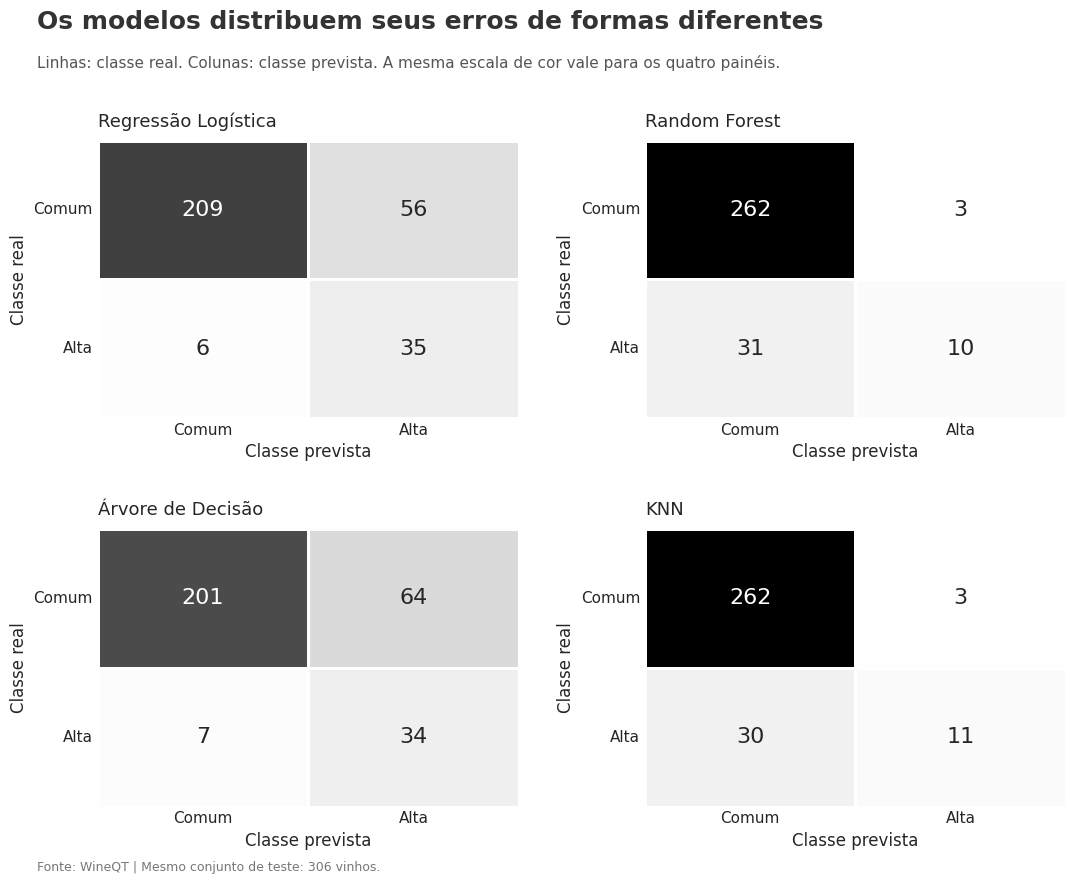

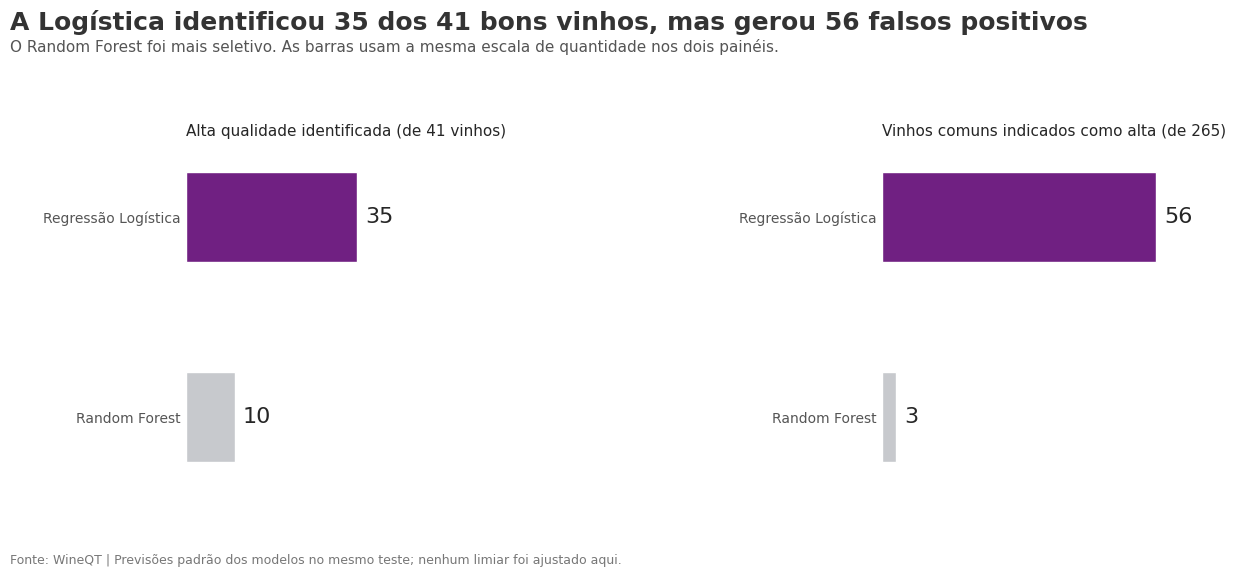

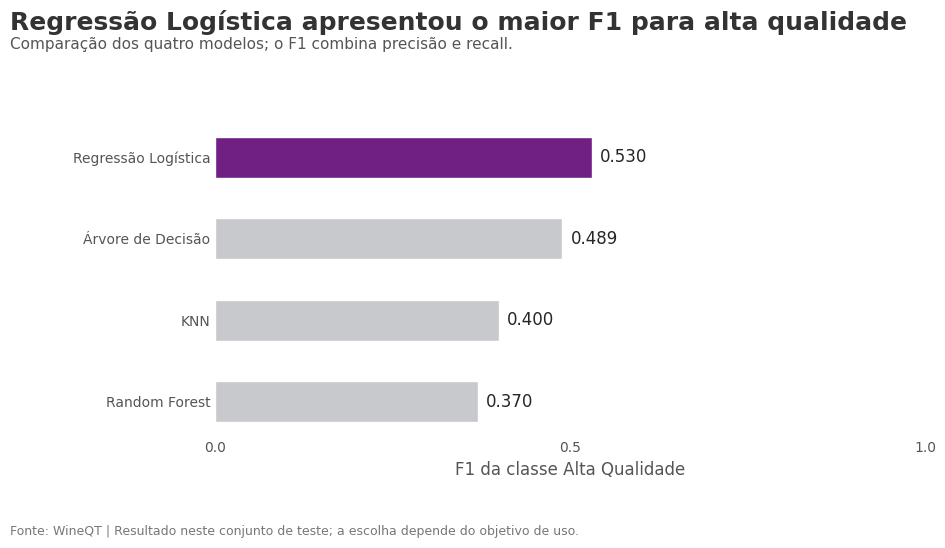

In [62]:
# Ajuste visual: matrizes mantidas com escala comum e leitura complementar
# dos dois tipos de erro. Todos os valores vêm das previsões já calculadas.
fig, axes = plt.subplots(2,2,figsize=(11,9))
limite=max(confusion_matrix(y_test,p,labels=[0,1]).max() for p in previsoes.values())
for ax,(nome,pred) in zip(axes.flat,previsoes.items()):
    cm=confusion_matrix(y_test,pred,labels=[0,1])
    sns.heatmap(cm,annot=True,fmt="d",cmap="Greys",cbar=False,vmin=0,vmax=limite,
                xticklabels=["Comum","Alta"],yticklabels=["Comum","Alta"],
                linewidths=2,linecolor="white",annot_kws={"size":16},ax=ax)
    ax.set_title(nome,loc="left",fontsize=13,pad=10)
    ax.set_xlabel("Classe prevista"); ax.set_ylabel("Classe real")
    ax.tick_params(length=0,rotation=0)
swd_titulo(fig,"Os modelos distribuem seus erros de formas diferentes",
           "Linhas: classe real. Colunas: classe prevista. A mesma escala de cor vale para os quatro painéis.",
           f"Fonte: WineQT | Mesmo conjunto de teste: {len(y_test)} vinhos.")
fig.subplots_adjust(top=0.83,bottom=0.09,left=0.09,right=0.97,hspace=0.40,wspace=0.30)
swd_salvar(fig,"matrizes_confusao.png")

swd_nomes=["Regressão Logística","Random Forest"]
swd_cms=[confusion_matrix(y_test,previsoes[n],labels=[0,1]) for n in swd_nomes]
swd_tp=[int(m[1,1]) for m in swd_cms]; swd_fp=[int(m[0,1]) for m in swd_cms]
fig, axes=plt.subplots(1,2,figsize=(13,5.8))
limite=max(swd_tp+swd_fp+[int(y_test.sum())])*1.30
for ax,valores,titulo in zip(axes,[swd_tp,swd_fp],
    [f"Alta qualidade identificada (de {int(y_test.sum())} vinhos)",
     f"Vinhos comuns indicados como alta (de {int((y_test==0).sum())})"]):
    barras=ax.barh(swd_nomes,valores,color=[SWD_ROXO,SWD_CINZA],height=0.45)
    ax.bar_label(barras,padding=6,fontsize=16)
    ax.invert_yaxis(); ax.set_xlim(0,limite); ax.set_xticks([])
    swd_limpar(ax); ax.set_title(titulo,loc="left",fontsize=11,pad=16)
swd_titulo(fig,f"A Logística identificou {swd_tp[0]} dos {int(y_test.sum())} bons vinhos, mas gerou {swd_fp[0]} falsos positivos",
           "O Random Forest foi mais seletivo. As barras usam a mesma escala de quantidade nos dois painéis.",
           "Fonte: WineQT | Previsões padrão dos modelos no mesmo teste; nenhum limiar foi ajustado aqui.")
fig.subplots_adjust(top=0.72,bottom=0.17,left=0.17,right=0.98,wspace=0.95)
swd_salvar(fig,"identificacao_e_falsos_positivos.png")

swd_f1=comparativo["F1"].sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(10,5.5))
barras=ax.barh(swd_f1.index,swd_f1.values,
                color=[SWD_ROXO if n==swd_f1.idxmax() else SWD_CINZA for n in swd_f1.index],height=0.5)
ax.bar_label(barras,fmt="%.3f",padding=6,fontsize=12)
ax.invert_yaxis(); ax.set_xlim(0,1); ax.set_xticks([0,0.5,1]); swd_limpar(ax)
ax.set_xlabel("F1 da classe Alta Qualidade",color=SWD_ESCURO)
swd_titulo(fig,f"{swd_f1.idxmax()} apresentou o maior F1 para alta qualidade",
           "Comparação dos quatro modelos; o F1 combina precisão e recall.",
           "Fonte: WineQT | Resultado neste conjunto de teste; a escolha depende do objetivo de uso.")
fig.subplots_adjust(top=0.77,bottom=0.20,left=0.24,right=0.95)
swd_salvar(fig,"comparacao_f1.png")

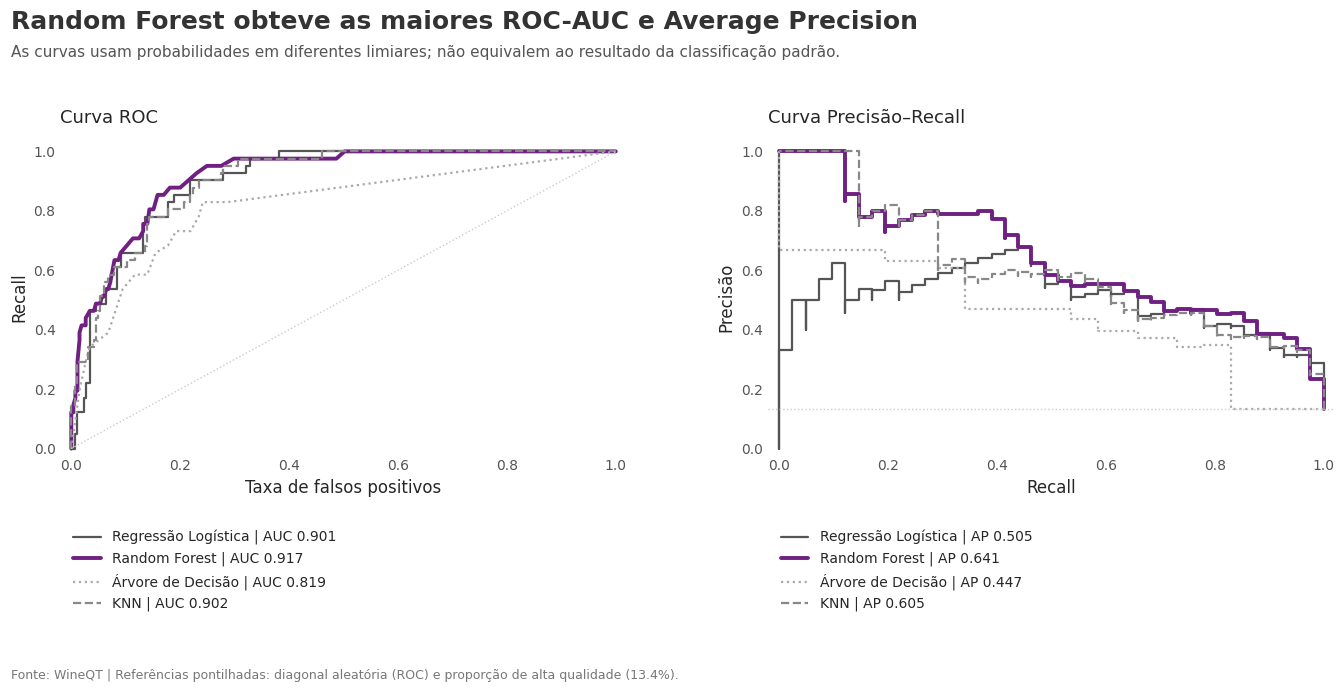

In [63]:
# Ajuste visual: RF em roxo para evidenciar suas métricas de ordenação.
# Os quatro modelos permanecem visíveis; traços distinguem as curvas em cinza.
fig,axes=plt.subplots(1,2,figsize=(14,7))
estilos={"Regressão Logística":("#555555","-"),
         "Random Forest":(SWD_ROXO,"-"),
         "Árvore de Decisão":("#AAAAAA",":"),"KNN":("#888888","--")}
for nome,prob in probabilidades.items():
    fpr,tpr,_=roc_curve(y_test,prob)
    precisao,recall,_=precision_recall_curve(y_test,prob)
    auc=roc_auc_score(y_test,prob); ap=average_precision_score(y_test,prob)
    cor,traco=estilos[nome]
    estilo=dict(color=cor,linestyle=traco,linewidth=2.8 if nome=="Random Forest" else 1.6)
    axes[0].plot(fpr,tpr,label=f"{nome} | AUC {auc:.3f}",**estilo)
    axes[1].step(recall,precisao,where="post",label=f"{nome} | AP {ap:.3f}",**estilo)
axes[0].plot([0,1],[0,1],":",color="#CCCCCC",linewidth=1)
axes[1].axhline(y_test.mean(),linestyle=":",color="#CCCCCC",linewidth=1)
for ax,titulo,xlab,ylab in zip(axes,["Curva ROC","Curva Precisão–Recall"],
    ["Taxa de falsos positivos","Recall"],["Recall","Precisão"]):
    swd_limpar(ax); ax.set(xlim=(-0.02,1.02),ylim=(-0.02,1.04),xlabel=xlab,ylabel=ylab)
    ax.set_title(titulo,loc="left",fontsize=13,pad=12)
    ax.legend(loc="upper left",bbox_to_anchor=(0,-0.20),frameon=False,fontsize=10)
swd_titulo(fig,"Random Forest obteve as maiores ROC-AUC e Average Precision",
           "As curvas usam probabilidades em diferentes limiares; não equivalem ao resultado da classificação padrão.",
           f"Fonte: WineQT | Referências pontilhadas: diagonal aleatória (ROC) e proporção de alta qualidade ({y_test.mean():.1%}).")
fig.subplots_adjust(top=0.79,bottom=0.34,left=0.07,right=0.98,wspace=0.25)
swd_salvar(fig,"curvas_modelos.png")

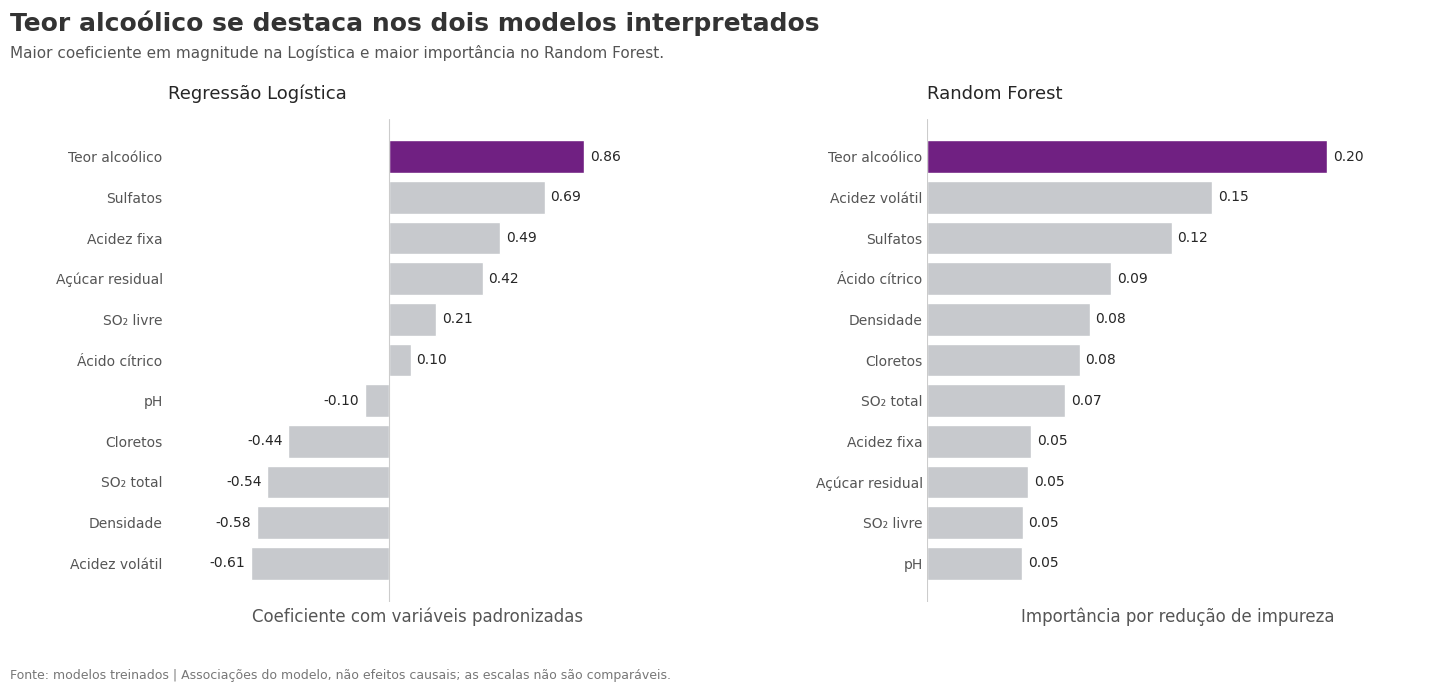

In [64]:
# Interpretação dos dois modelos destacados na discussão final.
# Coeficientes e importâncias são medidas diferentes, sem comparação direta.
# O destaque indica a maior magnitude em cada painel; não demonstra causalidade.
coef_lr = pd.Series(modelo_lr.coef_[0], index=x_train.columns).sort_values()
imp_rf = pd.Series(modelo_rf.feature_importances_, index=x_train.columns).sort_values()
fig,axes=plt.subplots(1,2,figsize=(15,7))
for ax,serie,titulo,xlab in zip(axes,[coef_lr,imp_rf],
    ["Regressão Logística","Random Forest"],
    ["Coeficiente com variáveis padronizadas","Importância por redução de impureza"]):
    destaque=serie.abs().idxmax()
    barras=ax.barh([SWD_NOMES.get(c,c) for c in serie.index],serie.values,
                    color=[SWD_ROXO if c==destaque else SWD_CINZA for c in serie.index])
    ax.bar_label(barras,fmt="%.2f",padding=4,fontsize=10)
    swd_limpar(ax); ax.axvline(0,color="#CCCCCC",linewidth=0.8)
    ax.set_xticks([]); ax.margins(x=0.25)
    ax.set_title(titulo,loc="left",fontsize=13,pad=14); ax.set_xlabel(xlab,color=SWD_ESCURO)
swd_titulo(fig,"Teor alcoólico se destaca nos dois modelos interpretados",
           "Maior coeficiente em magnitude na Logística e maior importância no Random Forest.",
           "Fonte: modelos treinados | Associações do modelo, não efeitos causais; as escalas não são comparáveis.")
fig.subplots_adjust(top=0.82,bottom=0.13,left=0.14,right=0.98,wspace=0.52)
swd_salvar(fig,"interpretacao_modelos.png")

In [65]:
# Observação sobre o código original:
# o Random Forest recebe x_train_scaled e x_test_scaled,
# apesar de o comentário anterior mencionar dados originais.
# Esse comportamento foi preservado nesta integração.

In [66]:
#fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Matriz da Regressão Logística
#sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues', ax=axes[0])
#axes[0].set_title('Matriz de Confusão - Regressão Logística')
#axes[0].set_xlabel('Previsto')
#axes[0].set_ylabel('Real')

# Matriz do Random Forest
#sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Greens', ax=axes[1])
#axes[1].set_title('Matriz de Confusão - Random Forest')
#axes[1].set_xlabel('Previsto')
#axes[1].set_ylabel('Real')

#plt.tight_layout()
#plt.savefig("matriz_confusao.png", dpi=150)
#plt.show()

# Etapa 6: Interpretação dos Resultados

## 6.1 - Identificando as Variáveis de Maior Influência

Como utilizamos o Random Forest, podemos extrair facilmente quais características físico-químicas o modelo considerou mais importantes para prever a alta qualidade do vinho.

/tmp/ipykernel_705/4105290721.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Feature', data=feature_importance.head(10), palette='viridis')


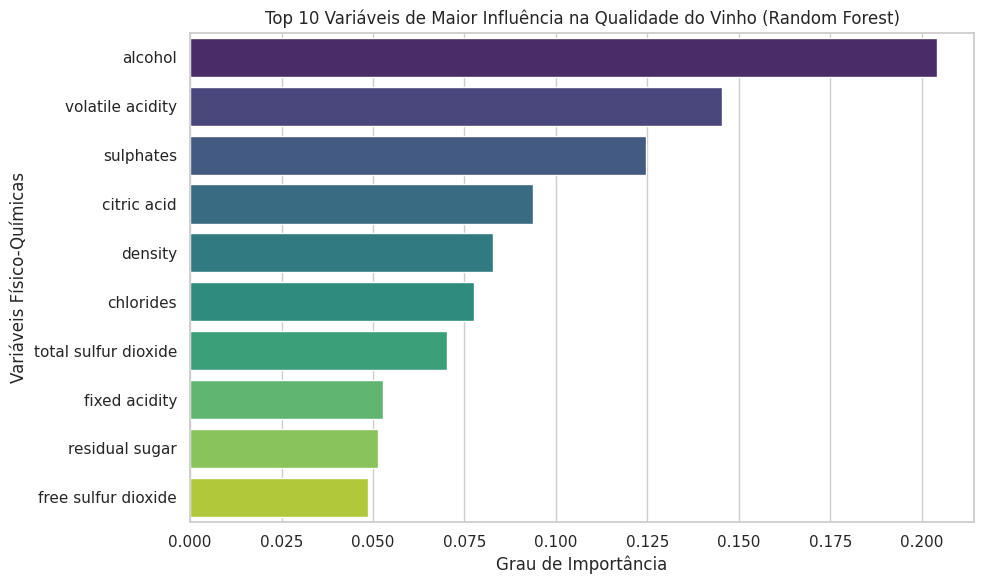

                 Feature  Importancia
10               alcohol     0.204091
1       volatile acidity     0.145394
9              sulphates     0.124549
2            citric acid     0.093720
7                density     0.082841
4              chlorides     0.077735
6   total sulfur dioxide     0.070353
0          fixed acidity     0.052862
3         residual sugar     0.051463
5    free sulfur dioxide     0.048668
8                     pH     0.048322


In [67]:
# Criando um DataFrame com a importância das features utilizando as colunas usadas no treino
feature_importance = pd.DataFrame({
    'Feature': x_train.columns,
    'Importancia': modelo_rf.feature_importances_
}).sort_values(by='Importancia', ascending=False)

# Plotando o gráfico das 10 principais variáveis
plt.figure(figsize=(10, 6))
sns.barplot(x='Importancia', y='Feature', data=feature_importance.head(10), palette='viridis')
plt.title('Top 10 Variáveis de Maior Influência na Qualidade do Vinho (Random Forest)')
plt.xlabel('Grau de Importância')
plt.ylabel('Variáveis Físico-Químicas')
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

print(feature_importance)

**Teor alcoólico:** apresentou a maior importância no Random Forest. Na análise exploratória, também observamos maior mediana de teor alcoólico entre os vinhos de alta qualidade.

**Sulfatos:** contribuíram para as previsões do modelo e apresentaram maior mediana entre os vinhos de alta qualidade.

**Acidez volátil:** foi uma característica relevante para o modelo. Na análise exploratória, os vinhos de alta qualidade apresentaram menor mediana dessa variável.

A importância das variáveis indica sua contribuição para as decisões do modelo, mas não informa, sozinha, se valores maiores aumentam ou diminuem a previsão de alta qualidade. Também não demonstra que alterar essas características causará uma melhora no vinho. Os resultados podem orientar investigações, que precisariam ser avaliadas por especialistas e por testes específicos.

## 6.2 - Analisando erros do modelo Random Forest

In [68]:
# Criando o DataFrame para análise dos erros no conjunto de teste
df_erros = x_test.copy()
df_erros['Real'] = y_test.values
df_erros['Previsto'] = y_pred_rf

# Separando em Acertos e Erros
df_erros['Status'] = 'Acerto'
df_erros.loc[df_erros['Real'] != df_erros['Previsto'], 'Status'] = 'Erro'

# Filtrando apenas as amostras onde o modelo errou
amostras_erros = df_erros[df_erros['Status'] == 'Erro']

print(f"Total de erros cometidos pelo Random Forest: {len(amostras_erros)} do total de {len(x_test)} amostras de teste.")

# Média das principais variáveis físico-químicas dividida por tipo de erro
# Falsos Negativos (Real=1, Previsto=0) vs Falsos Positivos (Real=0, Previsto=1)
tabela_comparativa = amostras_erros.groupby(['Real', 'Previsto'])[['alcohol', 'volatile acidity', 'sulphates', 'citric acid']].mean()

# Identificando cada grupo pelos valores reais e previstos,
# sem depender da posição das linhas na tabela.
rotulos = []

for real, previsto in tabela_comparativa.index:
    quantidade = len(
        amostras_erros[
            (amostras_erros["Real"] == real)
            & (amostras_erros["Previsto"] == previsto)
        ]
    )

    if real == 1 and previsto == 0:
        rotulo = f"Falso negativo (Alta prevista como Comum) [n={quantidade}]"
    else:
        rotulo = f"Falso positivo (Comum previsto como Alta) [n={quantidade}]"

    rotulos.append(rotulo)

tabela_comparativa.index = pd.Index(
    rotulos,
    name="Tipo de Erro"
)

display(tabela_comparativa.round(2))

Total de erros cometidos pelo Random Forest: 34 do total de 306 amostras de teste.


,alcohol,volatile acidity,sulphates,citric acid
Tipo de Erro,,,,
Falso positivo (Comum previsto como Alta) [n=3],11.63,0.44,0.88,0.50
Falso negativo (Alta prevista como Comum) [n=31],11.51,0.41,0.73,0.38


### Diagnóstico de erros do modelo Random Forest

O Random Forest cometeu 34 erros nos 306 vinhos do conjunto de teste.

1. **Falsos negativos — 31 vinhos:** eram de alta qualidade, mas foram classificados como comuns. Nesse grupo, as médias foram de 11,51% de teor alcoólico, 0,41 de acidez volátil e 0,73 de sulfatos.

2. **Falsos positivos — 3 vinhos:** eram comuns, mas foram classificados como de alta qualidade. Nesse grupo, as médias foram de 11,63% de teor alcoólico, 0,44 de acidez volátil e 0,88 de sulfatos.

Essas médias descrevem os grupos de erros, mas não permitem afirmar, isoladamente, qual característica causou cada classificação incorreta.

Entre os 13 vinhos indicados como de alta qualidade, o modelo acertou 10, apresentando precisão de aproximadamente 76,9%. Porém, identificou apenas 10 dos 41 vinhos de alta qualidade presentes no teste, com recall de aproximadamente 24,4%.

Portanto, o modelo foi seletivo nas indicações, mas deixou de identificar muitos vinhos de alta qualidade.

# Etapa 7: Principais Conclusões

## 7.1 — O que observamos nos dados

* Após a remoção das duplicatas, a base ficou com 1.018 vinhos. Desses, 137 foram classificados como de alta qualidade, com nota igual ou superior a 7. Isso representa aproximadamente 13,5% da base.
* Desafio de Classes Desbalanceadas: A conversão da variável de qualidade em uma classificação binária revelou um cenário desbalanceado. Utilizamos o ajuste de pesos (class_weight='balanced') na Regressão Logística, no Random Forest e na Árvore de Decisão para dar maior peso à classe minoritária durante o treinamento. Como a maioria dos vinhos pertence à classe comum, um modelo pode apresentar uma acurácia alta e, mesmo assim, identificar poucos vinhos de alta qualidade. Por isso, analisamos também precisão, recall e F1.
* Na análise exploratória, os vinhos de alta qualidade apresentaram maior teor alcoólico e menor acidez volátil nas medianas. Os sulfatos também apresentaram valores maiores nessa classe.
* O teor alcoólico se destacou tanto na Regressão Logística quanto no Random Forest. Esses resultados mostram associações nos dados e nos modelos. Eles não permitem concluir que aumentar o álcool ou modificar outra característica, isoladamente, melhorará a qualidade do vinho.

## 7.2 — O que aprendemos com a comparação dos modelos

Foram comparados quatro modelos: Regressão Logística, Random Forest, Árvore de Decisão e KNN. Todos utilizaram a mesma divisão de treino e teste.

O conjunto de teste continha 306 vinhos, dos quais 41 eram de alta qualidade.

A Regressão Logística identificou corretamente 35 desses 41 vinhos. Porém, também classificou 56 vinhos comuns como de alta qualidade. Portanto, encontrou boa parte dos vinhos de interesse, mas produziu mais indicações incorretas.

O Random Forest identificou corretamente 10 dos 41 vinhos de alta qualidade e classificou 3 vinhos comuns como de alta qualidade. Suas indicações foram mais precisas que as da Regressão Logística, mas ele deixou de identificar 31 vinhos de alta qualidade.

A Regressão Logística apresentou o maior F1 para a classe de alta qualidade neste teste, enquanto o Random Forest apresentou as maiores ROC-AUC e Average Precision. Essas métricas avaliam aspectos diferentes do desempenho, por isso não apontaram necessariamente para o mesmo modelo.

## 7.3 — Uso proposto e escolha do modelo

Para este trabalho, propomos o uso do modelo como uma triagem para encaminhar possíveis vinhos de alta qualidade à avaliação de especialistas.

Considerando esse objetivo, indicamos a Regressão Logística como modelo principal, pois identificou uma parcela maior dos vinhos de alta qualidade no teste.

Essa escolha pressupõe que seja possível avaliar também os vinhos comuns encaminhados incorretamente. Caso a prioridade fosse reduzir essas indicações incorretas, o Random Forest mereceria maior atenção.

O modelo seria um apoio à avaliação humana. Os resultados obtidos ainda não justificam seu uso para decidir automaticamente a classificação comercial de um vinho.

## 7.4 — Possíveis implicações para a produção

As características destacadas podem ajudar a equipe a acompanhar os lotes e investigar diferenças entre vinhos comuns e de alta qualidade.

Por exemplo, teor alcoólico, acidez volátil e sulfatos podem ser analisados em conjunto com a avaliação sensorial e com informações do processo produtivo.

Qualquer alteração no processo precisaria ser avaliada por profissionais da área e testada de forma controlada. Nosso estudo não determina valores ideais dessas características para produzir um vinho melhor.

## 7.5 — Limitações e aprendizado

Este trabalho foi desenvolvido como um exercício de aprendizagem em análise de dados e classificação. Buscamos compreender as etapas, comparar os resultados e reconhecer as limitações dos modelos.

A base é relativamente pequena e possui poucos vinhos de alta qualidade. Além disso, os resultados finais foram obtidos em uma única divisão de treino e teste. Uma divisão diferente pode produzir resultados diferentes.

Também não avaliamos o desempenho em novos lotes de uma vinícola. Por isso, não podemos garantir que os mesmos resultados ocorreriam em uma aplicação real.

Como continuidade, seria importante avaliar os modelos com novos dados e estudar os custos dos diferentes tipos de erro.

O principal aprendizado foi que escolher um modelo não depende apenas de obter uma métrica alta. É necessário entender quais erros ele comete e se esses erros são aceitáveis para o uso proposto.
